# Case study 2: nonlinear impact

This notebook reproduces the second case study of the paper with the library. It simulates impacts whose contact
force follows the nonlinear law of Hunt and Crossley:

$$F = K\,\delta^{3/2}\left(1 + \frac{\chi}{K}\,\dot{\delta}\right), \qquad
\chi = \frac{3K(1-e)}{2\,v_{approach}}~,$$

where $\delta$ is the indentation, $\dot{\delta}$ is the indentation velocity, $K$ is the contact stiffness,
$e$ is the coefficient of restitution, and $v_{approach}$ is the approach velocity. The dataset has twenty impacts:
five approach velocities combined with four coefficients of restitution.

The complete dataset has about 300,000 samples and takes about one hour to train. To keep this notebook short, it
first runs a version sampled ten times more coarsely (about 30,000 samples and ten minutes of training). It then
explains the study of the paper and places one example trial of each noise level, run on the complete dataset,
next to the values reported in the paper.

In [1]:
import os
import sys

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")     # quieter TensorFlow
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")    # these small networks train faster on the CPU
sys.path.insert(0, os.path.abspath(".."))              # use the library from this repository

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import figstyle
import twn2n

figstyle.apply()

sys.path.insert(0, os.path.abspath("../paper"))
import cases
from twn2n import benchmarks

## 1. Benchmark and noise

Each record covers one impact, from the first touch to the separation, and has five channels: the indentation
`x`, the indentation velocity `v`, the contact force `F_kN`, and two channels that are constant inside a record
and identify the test (the coefficient of restitution `e` and the approach velocity `v_approach`). Records have
different lengths, so they are passed to the library as a list.

Gaussian noise with a standard deviation of 10% of the standard deviation of each signal (a nominal input SNR of
20 dB in each impact) is added to the three measured channels. The two test conditions are known and stay
noise-free. The SNR values printed after the training pool the twenty impacts, so they differ slightly from the
nominal value.

20 impacts, 29962 samples, channels ('x', 'v', 'F_kN', 'e', 'v_approach')


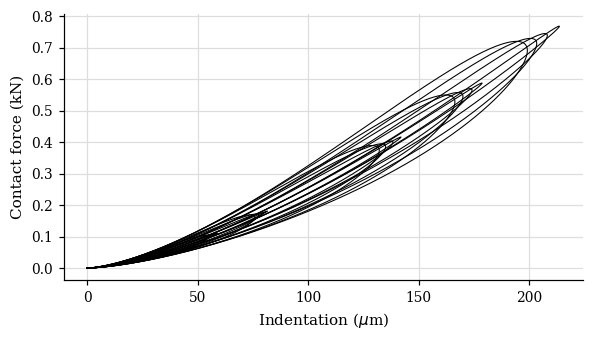

In [2]:
clean, times = benchmarks.hunt_crossley_impacts(n_eval=100_000)        # the paper uses n_eval = 1,000,000
noisy = twn2n.add_noise(clean, "white", snr_db=20.0, rng=0, channels=[0, 1, 2], exact_snr=False)

print(f"{len(clean)} impacts, {sum(len(r) for r in clean)} samples, channels {benchmarks.IMPACT_CHANNELS}")
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for record in clean:
    ax.plot(1e6 * record[:, 0], record[:, 2], color="#000000", linewidth=0.7)
ax.set_xlabel("Indentation ($\\mu$m)")
ax.set_ylabel("Contact force (kN)")
plt.tight_layout()
plt.show()

## 2. Denoising with TWN2N

The settings are those of the paper for this dataset: `p = 2` (20 inputs for the five channels), a bottleneck of
three units, and the smaller of the two architectures of the library (`network="compact"`).

In [3]:
model = twn2n.TWN2N(p=2, r=3, network="compact", seed=0)
denoised = model.fit_denoise(noisy)

print(f"{model.n_parameters_} parameters | {model.epochs_run_} epochs (best: {model.best_epoch_}) | "
      f"{model.training_time_s_ / 60:.1f} min")
rows = []
for k, name in enumerate(("indentation", "velocity", "force")):
    rows.append({"signal": name, "input SNR (dB)": twn2n.snr_db(clean, noisy, channels=[k]),
                 "output SNR (dB)": twn2n.snr_db(clean, denoised, channels=[k])})
print(pd.DataFrame(rows).round(2).to_string(index=False))

4997 parameters | 400 epochs (best: 300) | 6.9 min
     signal  input SNR (dB)  output SNR (dB)
indentation           22.28            28.71
   velocity           19.95            30.80
      force           22.33            29.71


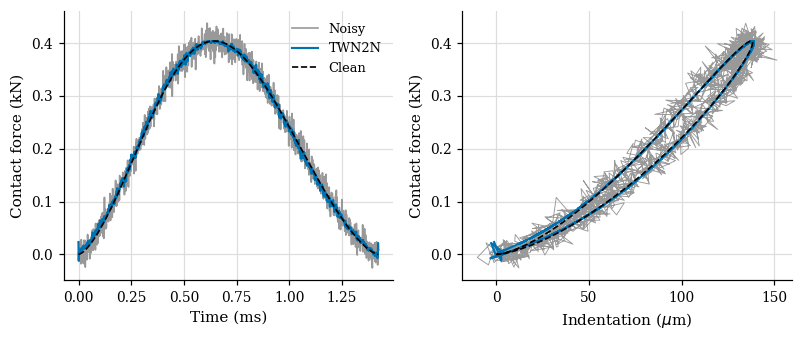

In [4]:
impact = 10                                  # v_approach = 0.3 m/s, e = 0.90
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.2))
time_ms = 1e3 * times[impact]
figstyle.line(axes[0], time_ms, noisy[impact][:, 2], "noisy")
figstyle.line(axes[0], time_ms, denoised[impact][:, 2], "twn2n", linewidth=1.4)
figstyle.line(axes[0], time_ms, clean[impact][:, 2], "clean")
axes[0].set_xlabel("Time (ms)")
axes[0].set_ylabel("Contact force (kN)")
axes[0].legend()
figstyle.line(axes[1], 1e6 * noisy[impact][:, 0], noisy[impact][:, 2], "noisy", linewidth=0.6)
figstyle.line(axes[1], 1e6 * denoised[impact][:, 0], denoised[impact][:, 2], "twn2n", linewidth=1.4)
figstyle.line(axes[1], 1e6 * clean[impact][:, 0], clean[impact][:, 2], "clean")
axes[1].set_xlabel("Indentation ($\\mu$m)")
axes[1].set_ylabel("Contact force (kN)")
plt.tight_layout()
plt.savefig("figures/impact_trial.png", bbox_inches="tight")
plt.show()

## 3. The study of the paper

The paper uses the dataset with 299,522 samples and five noise levels, in which the standard deviation of the
noise goes from 3% to 15% of that of each signal. Each level is repeated three times, with a different noise
realization and a different training seed in each trial.

The metric of the paper is a dimensionless distance between the estimated and the clean state: the errors of the
indentation, of the velocity, and of the force are divided by the standard deviation of the corresponding clean
signal and combined in a root mean square over the contact interval of each impact.

The values of the paper are stored in `paper/reference/impact_trials.csv`. As examples,
`paper/results/impact_trials.csv` stores one trial of each noise level run with this library on the complete
dataset. Other trials can be run with `paper/run.py`:

```bash
python paper/run.py impact --pct 10 --trials 0
python paper/run.py impact --study all --trials 0-2 --workers 5
```

Distance to the clean state
           input SNR (dB)   noisy  TWN2N, paper mean  TWN2N, paper min  TWN2N, paper max  TWN2N, example trial  reduction, example trial (%)
noise_pct                                                                                                                                   
3                 30.4576  0.0239             0.0129            0.0122            0.0133                0.0126                       47.1730
5                 26.0206  0.0399             0.0192            0.0180            0.0206                0.0173                       56.5342
7                 23.0980  0.0558             0.0234            0.0220            0.0243                0.0210                       62.3401
10                20.0000  0.0797             0.0293            0.0285            0.0310                0.0294                       63.1323
15                16.4782  0.1196             0.0415            0.0402            0.0425                0.0401                

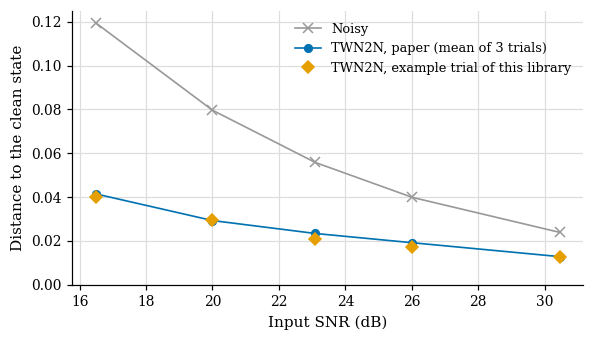

In [5]:
library = pd.read_csv("../paper/results/impact_trials.csv").set_index("noise_pct")
paper = pd.read_csv("../paper/reference/impact_trials.csv").groupby("noise_pct")

comparison = pd.DataFrame({
    "input SNR (dB)": paper.snr_db.mean(),
    "noisy": paper.noisy_distance.mean(),
    "TWN2N, paper mean": paper.twn2n_distance.mean(),
    "TWN2N, paper min": paper.twn2n_distance.min(), "TWN2N, paper max": paper.twn2n_distance.max(),
    "TWN2N, example trial": library.twn2n_distance,
})
comparison["reduction, example trial (%)"] = 100 * (1 - comparison["TWN2N, example trial"] / comparison["noisy"])
print("Distance to the clean state")
print(comparison.round(4).to_string())

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(comparison["input SNR (dB)"], comparison["noisy"], color=figstyle.COLORS["noisy"], marker="x", label="Noisy")
ax.plot(comparison["input SNR (dB)"], comparison["TWN2N, paper mean"], color=figstyle.COLORS["twn2n"], marker="o",
        markersize=5, label="TWN2N, paper (mean of 3 trials)")
ax.plot(comparison["input SNR (dB)"], comparison["TWN2N, example trial"], color=figstyle.COLORS["paper"], marker="D",
        markersize=6, linestyle="none", label="TWN2N, example trial of this library")
ax.set_xlabel("Input SNR (dB)")
ax.set_ylabel("Distance to the clean state")
ax.set_ylim(bottom=0)
ax.legend()
plt.tight_layout()
plt.savefig("figures/impact_distance.png", bbox_inches="tight")
plt.show()

The columns of the paper give the mean and the range of the three trials of each noise level. The error of each
variable is compared in [`paper/RESULTS.md`](../paper/RESULTS.md), and the tables of the paper are in
[`paper/TABLES.md`](../paper/TABLES.md).